# Bike Rental Prediction

## Project Overview

Bike-sharing systems provide an efficient and environmentally friendly mode of transportation in urban areas. The data generated by these systems can be used to understand rental patterns and predict future demand.

In this project, we will analyze bike rental data and build machine learning regression models to predict the **daily total number of bike rentals (`cnt`)** based on environmental, seasonal, weather, and calendar-related factors.
## Objectives

* Understand the structure and characteristics of the bike rental dataset.
* Perform data cleaning and preprocessing.
* Conduct exploratory data analysis (EDA) to identify important patterns and relationships.
* Analyze the impact of weather, season, temperature, humidity, and calendar-related factors on bike rentals.
* Build multiple regression models to predict daily bike rental demand.
* Compare model performance using appropriate regression evaluation metrics.
* Tune the best-performing model.
* Select the most suitable model for production.
* Document the challenges encountered and the techniques used to address them.


In [7]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display plots inside the notebook
%matplotlib inline

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

In [8]:
df = pd.read_csv("day.csv")# Load the bike rental dataset
df.head()# Display the first five rows

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### Dataset Dimensions and Columns
Before performing data cleaning and exploratory data analysis, we need to understand the size and structure of the dataset.
We will check:
* The number of rows and columns.
* The names of all variables.
* The data types of the variables.
This helps us understand what type of data we are working with and identify variables that may require preprocessing before model building.

In [9]:
# Check the number of rows and columns
df.shape

(731, 16)

In [10]:
# Display all column names
print(df.columns.tolist())

['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


In [11]:
# Check the data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [12]:
df.columns.tolist()

['instant',
 'dteday',
 'season',
 'yr',
 'mnth',
 'holiday',
 'weekday',
 'workingday',
 'weathersit',
 'temp',
 'atemp',
 'hum',
 'windspeed',
 'casual',
 'registered',
 'cnt']

In [14]:
# Generate statistical summary of numerical variables
df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [15]:
# Check the number of missing values in each column
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [16]:
# Check for duplicate row
df.duplicated().sum()

np.int64(0)

In [17]:
# Check numerical columns
df.select_dtypes(include=['int64', 'float64']).columns

Index(['instant', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual',
       'registered', 'cnt'],
      dtype='object')

In [18]:
# Check categorical columns
df.select_dtypes(include=['object', 'category']).columns

Index(['dteday'], dtype='object')

In [19]:
df['dteday'] = pd.to_datetime(df['dteday'])

In [20]:
df['dteday'].dtype

dtype('<M8[ns]')

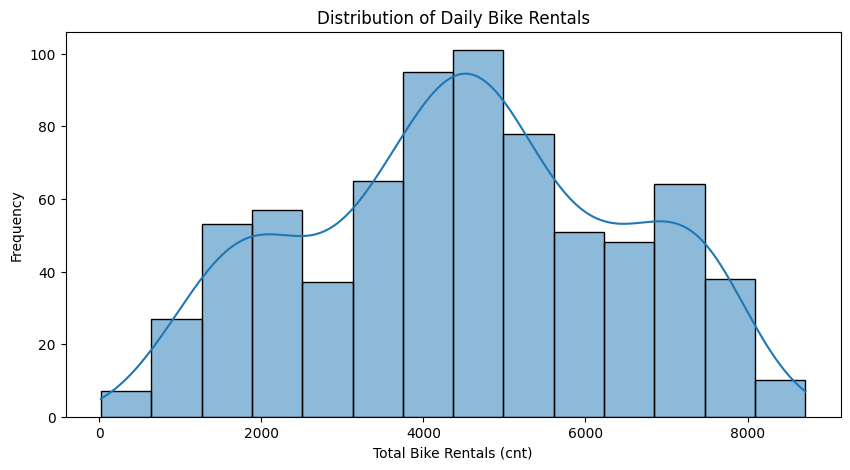

In [21]:
# Plot the distribution of the target variable

plt.figure(figsize=(10, 5))

sns.histplot(df['cnt'], kde=True)

plt.title('Distribution of Daily Bike Rentals')
plt.xlabel('Total Bike Rentals (cnt)')
plt.ylabel('Frequency')

plt.show()

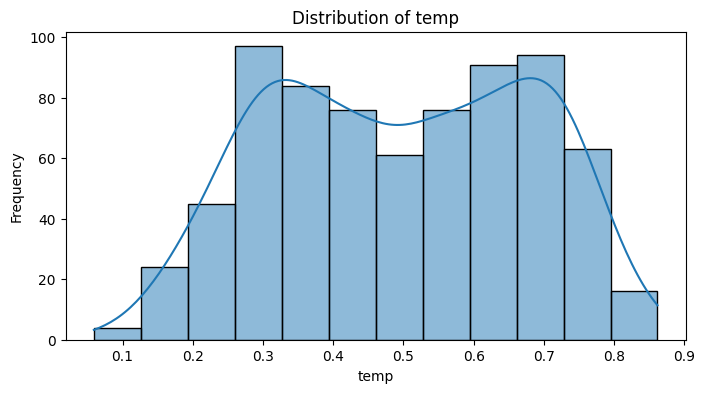

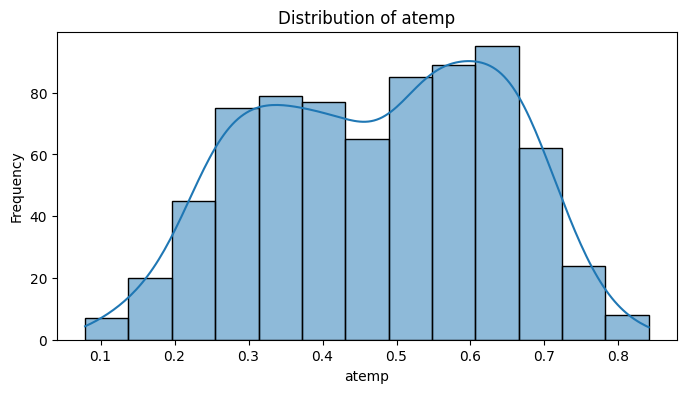

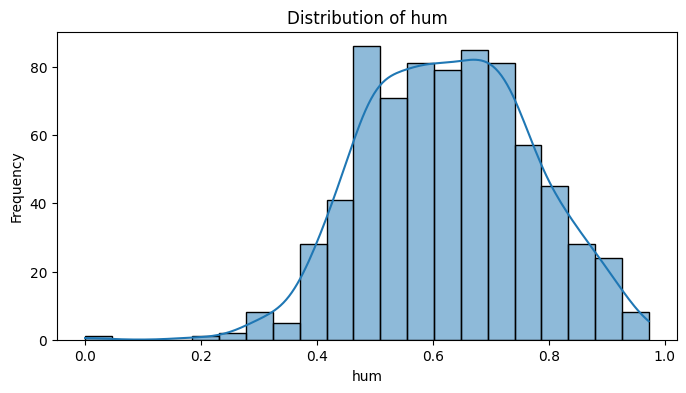

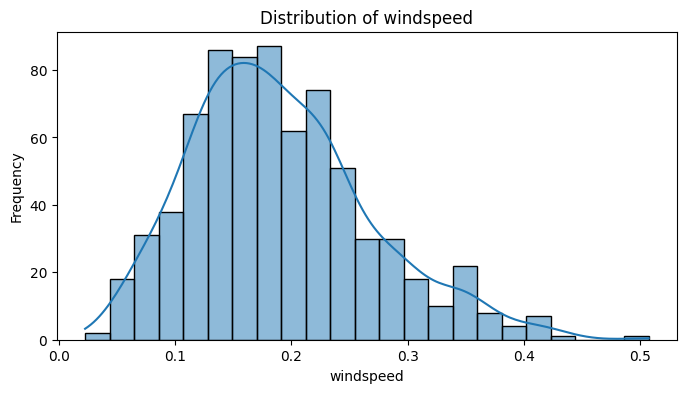

In [22]:
# Plot distributions of numerical environmental features

numerical_features = ['temp', 'atemp', 'hum', 'windspeed']

for column in numerical_features:
    
    plt.figure(figsize=(8, 4))
    
    sns.histplot(df[column], kde=True)
    
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    
    plt.show()

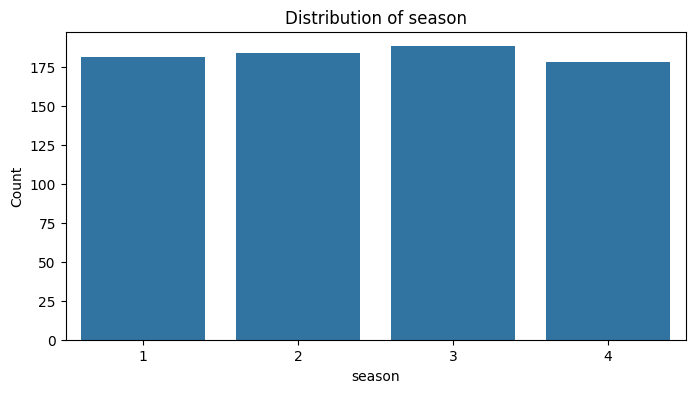

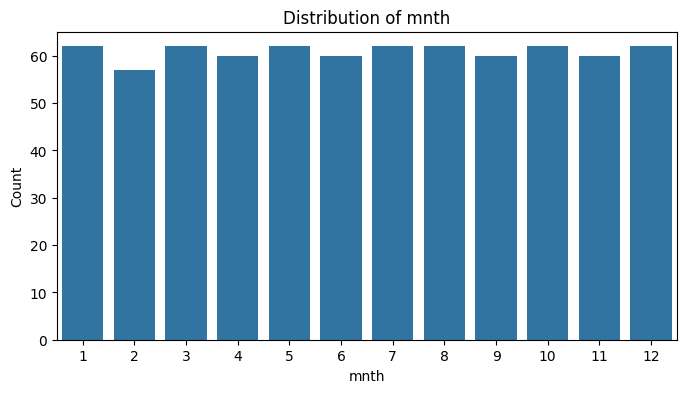

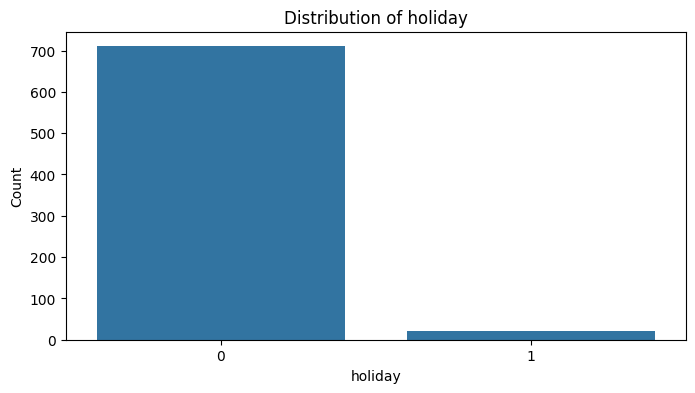

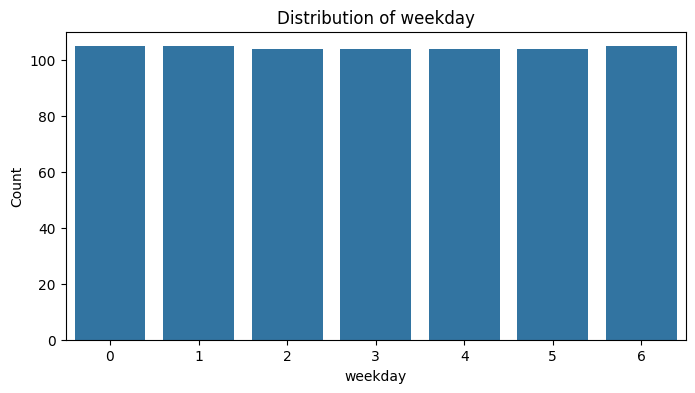

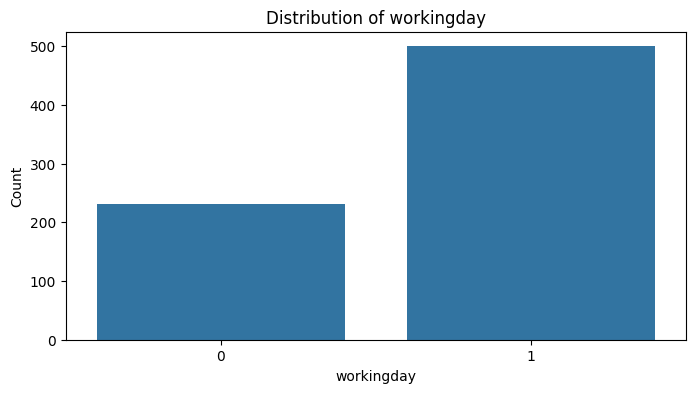

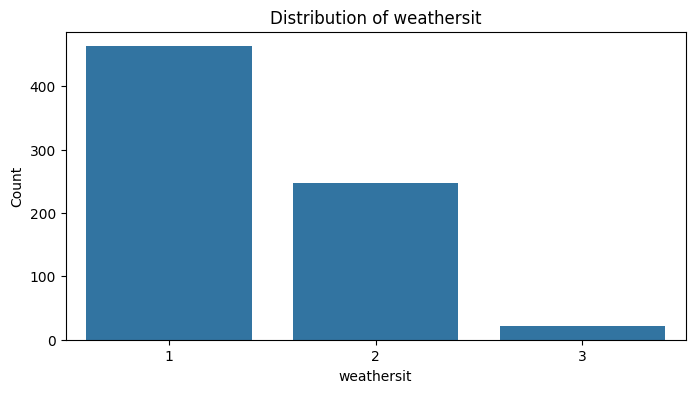

In [23]:
categorical_features = [
    'season',
    'mnth',
    'holiday',
    'weekday',
    'workingday',
    'weathersit'
]

for column in categorical_features:
    plt.figure(figsize=(8, 4))

    sns.countplot(data=df, x=column)

    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Count')

    plt.show()

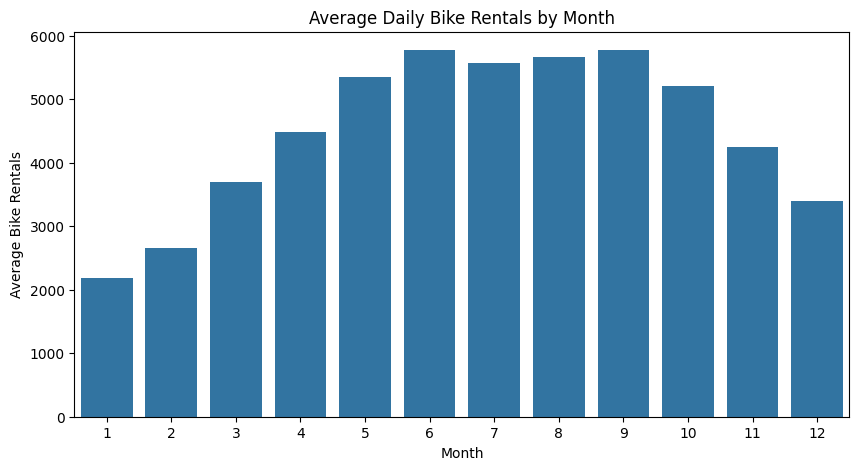

In [24]:
plt.figure(figsize=(10, 5))

sns.barplot(data=df, x='mnth', y='cnt', errorbar=None)

plt.title('Average Daily Bike Rentals by Month')
plt.xlabel('Month')
plt.ylabel('Average Bike Rentals')

plt.show()

### Interpretation of Categorical Feature Distributions

The count plots illustrate the frequency of observations across different seasons, months, weekdays, holidays, working days, and weather conditions.

These visualizations help identify how observations are distributed among categories and whether some categories occur more frequently than others. This provides a foundation for further analysis of how seasonal patterns, calendar conditions, and weather situations influence daily bike rental demand.

 These plots represent category frequencies, not rental demand. The relationship between each feature and total bike rentals (`cnt`) will be investigated in the next grah.


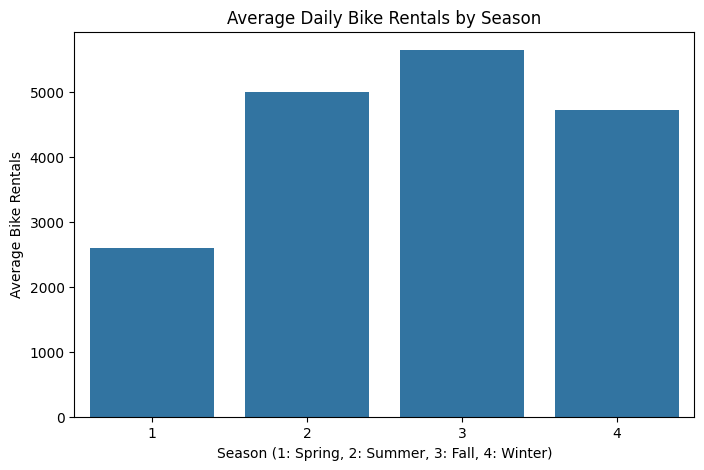

In [25]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x='season', y='cnt', errorbar=None)

plt.title('Average Daily Bike Rentals by Season')
plt.xlabel('Season (1: Spring, 2: Summer, 3: Fall, 4: Winter)')
plt.ylabel('Average Bike Rentals')

plt.show()

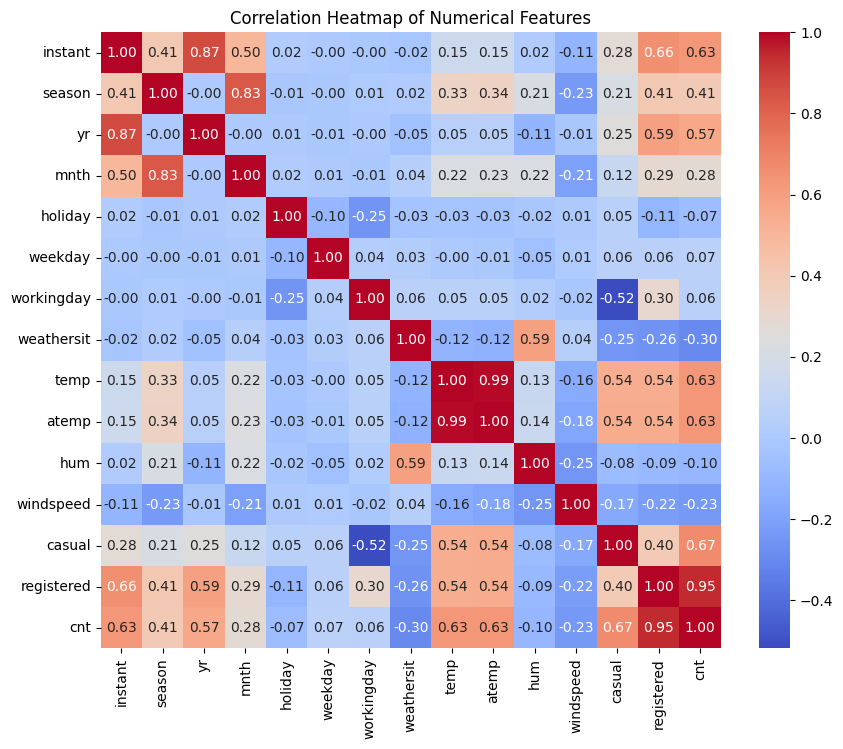

In [26]:
plt.figure(figsize=(10, 8))

correlation = df.select_dtypes(include='number').corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

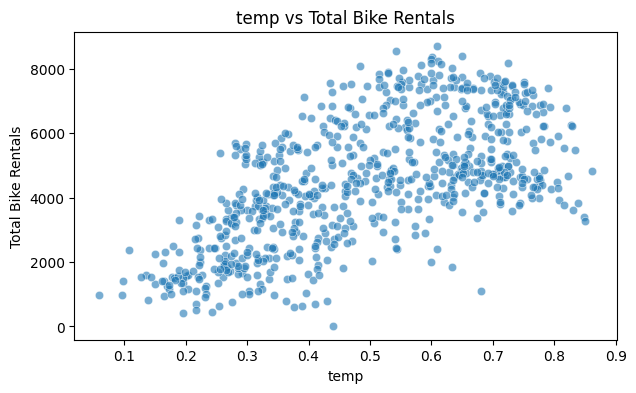

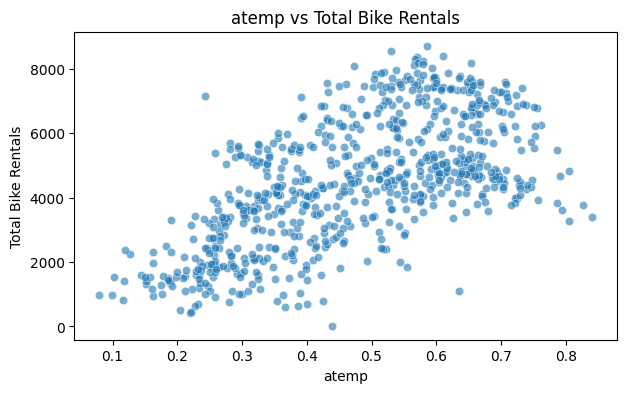

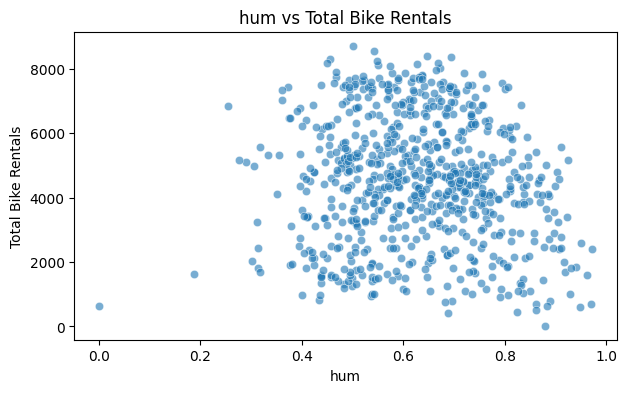

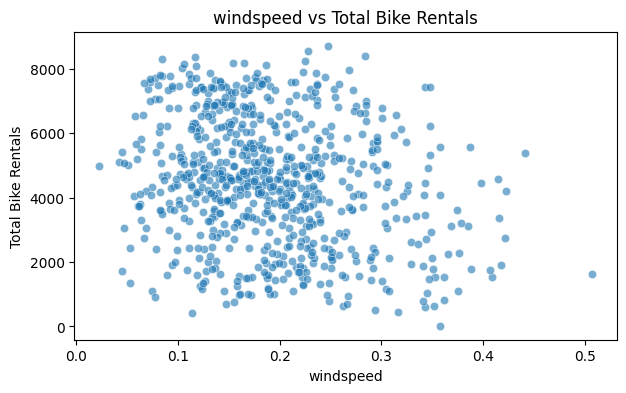

In [27]:
environmental_features = ['temp', 'atemp', 'hum', 'windspeed']

for column in environmental_features:
    plt.figure(figsize=(7, 4))

    sns.scatterplot(data=df, x=column, y='cnt', alpha=0.6)

    plt.title(f'{column} vs Total Bike Rentals')
    plt.xlabel(column)
    plt.ylabel('Total Bike Rentals')

    plt.show()

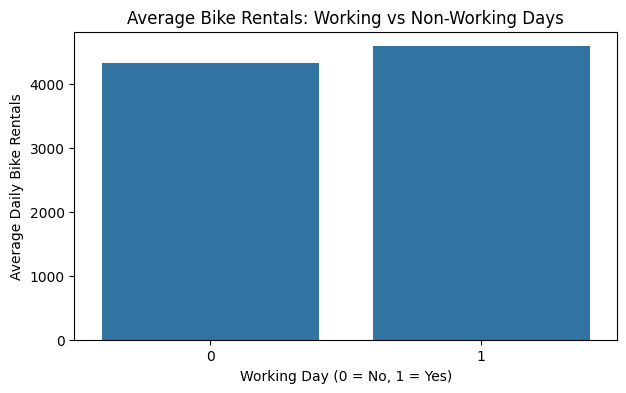

In [28]:
plt.figure(figsize=(7, 4))

sns.barplot(data=df, x='workingday', y='cnt', errorbar=None)

plt.title('Average Bike Rentals: Working vs Non-Working Days')
plt.xlabel('Working Day (0 = No, 1 = Yes)')
plt.ylabel('Average Daily Bike Rentals')

plt.show()

In [29]:
# Extract useful features from the date column
df['day'] = df['dteday'].dt.day
df['dayofyear'] = df['dteday'].dt.dayofyear
df['weekend'] = (df['weekday'] >= 5).astype(int)

# Display the new features
df[['dteday', 'day', 'dayofyear', 'weekday', 'weekend']].head()

,dteday,day,dayofyear,weekday,weekend
0,2011-01-01,1,1,6,1
1,2011-01-02,2,2,0,0
2,2011-01-03,3,3,1,0
3,2011-01-04,4,4,2,0
4,2011-01-05,5,5,3,0


In [30]:
df['weekend'] = df['weekday'].isin([0, 6]).astype(int)

In [31]:
# Check the dataset after feature engineering
print("Dataset shape:", df.shape)
print("\nNew columns:")
print(df[['day', 'dayofyear', 'weekend']].head())

print("\nMissing values in new features:")
print(df[['day', 'dayofyear', 'weekend']].isnull().sum())

Dataset shape: (731, 19)

New columns:
   day  dayofyear  weekend
0    1          1        1
1    2          2        1
2    3          3        0
3    4          4        0
4    5          5        0

Missing values in new features:
day          0
dayofyear    0
weekend      0
dtype: int64


In [32]:
# Separate the target variable
y = df['cnt']

# Select input features
X = df.drop(columns=['cnt', 'casual', 'registered', 'instant', 'dteday'])

# Check the shapes
print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

# Display the selected features
print("\nSelected input features:")
print(X.columns.tolist())

Input features shape: (731, 14)
Target variable shape: (731,)

Selected input features:
['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'day', 'dayofyear', 'weekend']


In [33]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Check the shapes of the datasets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (584, 14)
X_test shape: (147, 14)
y_train shape: (584,)
y_test shape: (147,)


In [34]:
# Import machine learning regression models

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.ensemble import GradientBoostingRegressor

# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print("All models and evaluation metrics imported successfully!")

All models and evaluation metrics imported successfully!


In [35]:
# Initialize all regression models

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

print("Models initialized successfully!")

for name in models:
    print(name)

Models initialized successfully!
Linear Regression
Decision Tree
Random Forest
Gradient Boosting


In [36]:
# Train all models

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully!")

print("All models have been trained successfully.")

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!
All models have been trained successfully.


In [37]:
# Store model evaluation results
results = []

# Evaluate every trained model
for name, model in models.items():

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = mean_squared_error(y_test, y_pred) ** 0.5
    r2 = r2_score(y_test, y_pred)

    # Store results
    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

# Create comparison table
results_df = pd.DataFrame(results)

# Display models sorted by R2 score
results_df = results_df.sort_values(
    by='R2 Score',
    ascending=False
).reset_index(drop=True)

results_df

,Model,MAE,RMSE,R2 Score
0,Gradient Boosting,450.876951,631.073832,0.900682
1,Random Forest,434.855714,680.501244,0.884515
2,Linear Regression,619.860443,828.565872,0.828793
3,Decision Tree,635.183673,914.698121,0.791347


In [38]:
# Compare training and testing R² scores

overfitting_results = []

for name, model in models.items():

    # Predictions on training and testing data
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Calculate R² scores
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    overfitting_results.append({
        'Model': name,
        'Train R2': train_r2,
        'Test R2': test_r2,
        'R2 Difference': train_r2 - test_r2
    })

overfitting_df = pd.DataFrame(overfitting_results)

overfitting_df.sort_values(
    by='Test R2',
    ascending=False
).reset_index(drop=True)

,Model,Train R2,Test R2,R2 Difference
0,Gradient Boosting,0.962261,0.900682,0.061579
1,Random Forest,0.983276,0.884515,0.098761
2,Linear Regression,0.794153,0.828793,-0.034640
3,Decision Tree,1.000000,0.791347,0.208653


In [39]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

gb_model = GradientBoostingRegressor(random_state=42)

param_grid = {
    'n_estimators': [100, 200],#Controls the number of boosting stages trees to evalute the model
    
    'learning_rate': [0.05, 0.1],#Controls how much each new tree contributes to the overall prediction.
    
    'max_depth': [2, 3],      #Controls the maximum depth of each tree & manage complexity
    
    'min_samples_split': [2, 5] #minimum number of samples required to split an internal tree node.
}

grid_search = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid,
    cv=5,  # evaluates each combination using five cross-validation fold
    scoring='r2',# Uses the R² score to compare model performance.
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation R2:", grid_search.best_score_)

Best Parameters: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_split': 5, 'n_estimators': 100}
Best Cross-Validation R2: 0.8809541487333183


In [40]:
# Get the best model identified by GridSearchCV
best_gb_model = grid_search.best_estimator_

# Generate predictions on the test dataset
y_pred_tuned = best_gb_model.predict(X_test)

# Calculate evaluation metrics
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_rmse = mean_squared_error(y_test, y_pred_tuned) ** 0.5
tuned_r2 = r2_score(y_test, y_pred_tuned)

# Display the results
print("Tuned Gradient Boosting Results")
print("--------------------------------")
print("Best Parameters:", grid_search.best_params_)
print(f"MAE: {tuned_mae:.2f}")
print(f"RMSE: {tuned_rmse:.2f}")
print(f"R² Score: {tuned_r2:.4f}")

Tuned Gradient Boosting Results
--------------------------------
Best Parameters: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_split': 5, 'n_estimators': 100}
MAE: 447.36
RMSE: 625.31
R² Score: 0.9025


In [41]:
# Compare original and tuned Gradient Boosting models
comparison_df = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R2 Score'],
    'Original Gradient Boosting': [450.88, 631.07, 0.9007],
    'Tuned Gradient Boosting': [tuned_mae, tuned_rmse, tuned_r2]
})

comparison_df

,Metric,Original Gradient Boosting,Tuned Gradient Boosting
0,MAE,450.8800,447.359892
1,RMSE,631.0700,625.308710
2,R2 Score,0.9007,0.902488


In [42]:
# Generate predictions on training and testing data
y_train_pred_tuned = best_gb_model.predict(X_train)
y_test_pred_tuned = best_gb_model.predict(X_test)

# Calculate R2 scores
train_r2_tuned = r2_score(y_train, y_train_pred_tuned)
test_r2_tuned = r2_score(y_test, y_test_pred_tuned)

# Display the results
print("Tuned Gradient Boosting - Overfitting Check")
print("-------------------------------------------")
print(f"Training R2 Score: {train_r2_tuned:.4f}")
print(f"Testing R2 Score:  {test_r2_tuned:.4f}")
print(f"R2 Difference:     {train_r2_tuned - test_r2_tuned:.4f}")

Tuned Gradient Boosting - Overfitting Check
-------------------------------------------
Training R2 Score: 0.9613
Testing R2 Score:  0.9025
R2 Difference:     0.0588


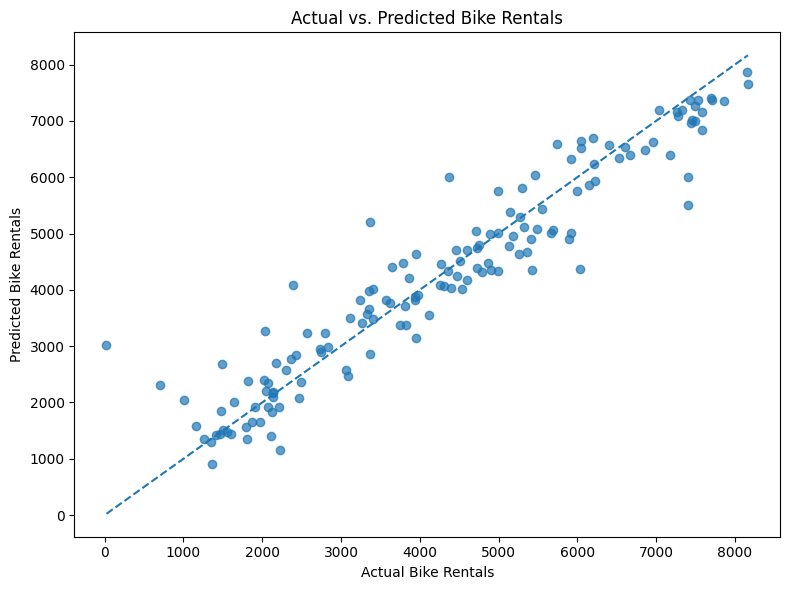

In [43]:
import matplotlib.pyplot as plt

# Plot actual values against predicted values
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_tuned, alpha=0.7)

# Add a reference line for perfect predictions
min_value = min(y_test.min(), y_pred_tuned.min())
max_value = max(y_test.max(), y_pred_tuned.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.title("Actual vs. Predicted Bike Rentals")
plt.tight_layout()
plt.show()

In [44]:
import joblib

joblib.dump(best_gb_model, 'bike_rental_gradient_boosting.pkl')

print("Final Bike Rental Prediction model saved successfully!")

Final Bike Rental Prediction model saved successfully!


## Project Summary

The objective of this project was to analyze bike rental data, identify important factors influencing rental demand, and build a machine learning model to predict the total number of bike rental
### Final Model Performance

The tuned Gradient Boosting Regressor achieved the following results on the test dataset
- **Mean Absolute Error (MAE):** 447.36
- **Root Mean Squared Error (RMSE):** 625.31
- **R² Score:** 0.9025
The R² score indicates that the model explains approximately 90.25% of the variation in bike rental counts on the test set.

### Business Insights
- Bike rental demand varies with seasonal and weather conditions.
- Understanding demand patterns can help operators plan bike availability.
- Predictive models can support resource allocation and rental service planning.
- Feature importance helps identify which input variables the model relies on most.